## 1. The task

Every graph in UPFD Gossipcop is the retweet cascade of one news story. The root is the news item. Every other node is a Twitter user who shared it, joined to the account they got it from.

For a cascade $G=(V,E,X)$ we predict one label $y\in\{0,1\}$ for the whole graph, fake or real. This is graph classification.

The model is a graph transformer, GraphGPS (Rampášek et al., 2022). In a GCN a node only hears from its neighbours, so information needs $L$ layers to travel $L$ hops. A graph transformer adds global self-attention: in every layer each node can attend to every other node of the same cascade. Positional encodings tell it where in the graph each node sits.

The plan is the same as for the GCN, so the two notebooks can be compared section by section: look at the data, tune on the validation split (Milestone 2), then run the six analyses of Milestone 3.

Kaggle already has PyTorch. We install PyTorch Geometric, and Captum for Integrated Gradients. Captum goes in without its pinned dependencies so that it leaves Kaggle's NumPy alone.

In [1]:
!pip install -q torch_geometric
!pip install -q --no-deps captum

## 2. Set the experiment budget

All the settings that control run time are here, with the same values as in the GCN notebook so both models get the same tuning budget.

A training run lasts at most `epochs` epochs and stops early once validation accuracy has not improved for `patience` epochs.

The search tries `n_trials` random configurations, each with every seed in `search_seeds`. The winner is retrained on ten fresh seeds, `final_seeds`, that were never used for selection. Ablations and robustness use the first five of them, `abl_seeds`.

`n_explain` is the number of test graphs we explain at the end.

In [2]:
epochs, patience = 200, 30
n_trials, search_seeds = 40, [0, 1, 2]
final_seeds = list(range(100, 110))
abl_seeds = final_seeds[:5]
n_explain = 100

## 3. Load the three official splits

PyG ships UPFD with a fixed split: 20% train, 10% validation and 70% test. We keep it, so all three models are compared on exactly the same graphs.

We use the `'content'` node features, a 310-dimensional vector per node.

The data goes to `/tmp` so that Kaggle does not copy 1.4 GB of raw files into the notebook output.

PyG warns on every max-pooling call that an optional package would make it faster, and PGExplainer warns on every training step. We silence just those two messages so they do not bury the results.

In [3]:
import torch
import warnings
from torch_geometric.datasets import UPFD
warnings.filterwarnings('ignore', message='.*can be accelerated via')
warnings.filterwarnings('ignore', message='Converting a tensor with requires_grad')

root = '/tmp/upfd'
raw = {s: UPFD(root, 'gossipcop', 'content', s) for s in ['train', 'val', 'test']}
device = 'cuda' if torch.cuda.is_available() else 'cpu'
for s in raw:
    print(s, "graphs =", len(raw[s]))
print("node features =", raw['train'].num_features, "   device =", device)

train graphs = 1092
val graphs = 546
test graphs = 3826
node features = 310    device = cuda


## 4. One cascade

A graph is stored as node features `x` of shape $|V|\times310$, an edge list `edge_index` of shape $2\times|E|$, and a label `y`.

In [4]:
g = raw['train'][0]
print(g)
print("first edges:", g.edge_index[:, :8].tolist())
print("label:", g.y.item())

Data(x=[76, 310], edge_index=[2, 75], y=[1])
first edges: [[0, 0, 0, 0, 0, 0, 0, 0], [1, 2, 3, 4, 5, 6, 7, 8]]
label: 0


## 5. Check the edge direction

A retweet cascade grows outwards from the news node. If each edge is stored once, as parent $\rightarrow$ child, messages can only flow away from the root.

We test three things on every graph: is it directed, is it a tree ($|E|=|V|-1$), and is node $0$ the root, i.e. the one node with no incoming edge.

In [5]:
from torch_geometric.utils import degree
graphs = [g for s in raw for g in raw[s]]
print("directed graphs:", sum(g.is_directed() for g in graphs), "of", len(graphs))
print("trees, |E| = |V| - 1:", sum(g.num_edges == g.num_nodes - 1 for g in graphs))
print("node 0 has no parent:", sum(degree(g.edge_index[1], g.num_nodes)[0].item() == 0 for g in graphs))

directed graphs: 5464 of 5464
trees, |E| = |V| - 1: 5464
node 0 has no parent: 5464


## 6. Undirected cascades and random-walk positional encodings

Attention on its own sees a set of nodes, not a graph. Positional encodings put the structure back. We use random-walk encodings (RWPE): for node $v$,

$p_v=\big[P_{vv},\,(P^2)_{vv},\,\ldots,\,(P^k)_{vv}\big]$, with $P=D^{-1}A$,

the probability that a random walk started at $v$ is back at $v$ after $1,\ldots,k$ steps. A leaf returns after two steps with probability $1$; the hub of a large star returns with probability $1/\deg$.

Two facts about our cascades decide how we compute them:

- On a directed tree no walk ever comes back, so every entry is $0$. We apply `ToUndirected()` first.
- A tree is bipartite, so a walk can only return after an even number of steps and the odd entries are always $0$. We take $k=16$ and keep the 8 even steps.

In [6]:
from torch_geometric.transforms import ToUndirected, AddRandomWalkPE
und, rw = ToUndirected(), AddRandomWalkPE(walk_length=16, attr_name='pe')

def add_pe(g):
    g = rw(g)
    g.pe = g.pe[:, 1::2]
    return g

g = raw['train'][0]
print("directed tree:   nonzero RWPE entries =", rw(g.clone()).pe.count_nonzero().item())
p = rw(und(g.clone())).pe
print("undirected tree: nonzero at odd steps =", p[:, 0::2].count_nonzero().item(), "   at even steps =", p[:, 1::2].count_nonzero().item(), "of", p[:, 1::2].numel())
train_set, val_set, test_set = [[add_pe(und(g)) for g in raw[s]] for s in raw]
print("positional encoding per node:", tuple(train_set[0].pe.shape))

directed tree:   nonzero RWPE entries = 0
undirected tree: nonzero at odd steps = 0    at even steps = 608 of 608
positional encoding per node: (76, 8)


## 7. Class balance and cascade size

If both classes are equally frequent, accuracy is a fair primary metric. We still report macro-F1 and ROC-AUC next to it.

In [7]:
import numpy as np, pandas as pd
y_train, y_val, y_test = [np.array([g.y.item() for g in d]) for d in [train_set, val_set, test_set]]
for s, y in zip(raw, [y_train, y_val, y_test]):
    print(s, "  class 0 =", (y == 0).sum(), "  class 1 =", (y == 1).sum())
counts = pd.DataFrame(dict(y=[g.y.item() for g in graphs], nodes=[g.num_nodes for g in graphs]))
print(counts.groupby('y').nodes.describe().round(1))

train   class 0 = 557   class 1 = 535
val   class 0 = 265   class 1 = 281
test   class 0 = 1910   class 1 = 1916
    count  mean   std  min   25%   50%   75%    max
y                                                  
0  2732.0  76.2  40.6  3.0  48.0  70.0  99.0  199.0
1  2732.0  38.9  41.8  3.0  11.0  22.0  50.0  198.0


## 8. How far does size alone go?

The classes are close to balanced in every split, but their cascades are not the same size: class 0 cascades are much larger than class 1 cascades.

So the number of nodes on its own already carries signal. A logistic regression on $\log|V|$, fitted on the training graphs, tells us how much. Every number below should be read against this one-feature baseline.

In [8]:
from sklearn.linear_model import LogisticRegression
logn = lambda d: np.log([[g.num_nodes] for g in d])
print("test accuracy from log|V| alone:", round(LogisticRegression().fit(logn(train_set), y_train).score(logn(test_set), y_test), 4))

test accuracy from log|V| alone: 0.7522


## 9. The two feature blocks

The 310 columns are described as a 300-dimensional text embedding followed by a 10-dimensional user-profile vector. We check this against the `'profile'` and `'spacy'` options of the same dataset by correlating matching columns over all training nodes.

In [9]:
X = torch.cat([g.x for g in train_set])
prof = torch.cat([g.x for g in UPFD(root, 'gossipcop', 'profile', 'train')])
spcy = torch.cat([g.x for g in UPFD(root, 'gossipcop', 'spacy', 'train')])
corr = lambda a, b: ((a - a.mean(0)) * (b - b.mean(0))).mean(0) / (a.std(0, correction=0) * b.std(0, correction=0))
print("last 10 columns vs 'profile', corr per column:", corr(X[:, 300:], prof).numpy().round(3))
print("first 300 columns vs 'spacy', median corr:   ", round(corr(X[:, :300], spcy).median().item(), 3))
print("all features in [", X.min().item(), ",", X.max().item(), "]")

last 10 columns vs 'profile', corr per column: [0.983 0.954 1.    0.999 0.986 0.998 1.    0.989 0.996 0.99 ]
first 300 columns vs 'spacy', median corr:    0.093
all features in [ 0.0 , 1.0000001192092896 ]


The last 10 columns are the profile vector, up to a rescaling. The first 300 columns are a text embedding, but not the same matrix that the `'spacy'` option returns, so from here on we simply call them the **text block** (columns 0 to 299) and the **profile block** (columns 300 to 309).

Every feature already lies in $[0,1]$, so no further scaling is needed.

## 10. The GPS layer

A GPS layer runs a local message-passing step and a global attention step side by side on the same input $X$, and adds them.

The local step is GIN: $h_i^{M}=\text{MLP}\big(h_i+\sum_{j\in N(i)}h_j\big)$. It only sees the cascade's edges.

The global step is multi-head self-attention over all nodes of the graph: $X^{T}=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}}\right)V$ with $Q=XW_Q$, $K=XW_K$, $V=XW_V$. It ignores the edges, so any two users can exchange information in one layer however far apart they are.

Each branch has a residual connection and batch norm, and the sum goes through a two-layer MLP, again with a residual:

$X' = Y + \text{MLP}(Y)$, where $Y = \text{BN}(X^{M}+X) + \text{BN}(X^{T}+X)$.

A single layer keeps the width of its input.

In [10]:
from torch_geometric.nn import GPSConv, GINConv, MLP
layer = GPSConv(16, GINConv(MLP([16, 16, 16], norm=None)), heads=4)
h = torch.randn(train_set[0].num_nodes, 16)
print("one GPS layer:", tuple(h.shape), "->", tuple(layer(h, train_set[0].edge_index).shape))

one GPS layer: (76, 16) -> (76, 16)


## 11. From nodes to one graph vector

Each node starts from its features and its positional encoding: $h_v^{(0)}=\big[W_x x_v \,\|\, W_p\,\text{BN}(p_v)\big]$, with 8 of the `hidden` dimensions given to the encoding.

After $L$ GPS layers a readout pools the node embeddings into one vector per graph, $h_G=\text{READOUT}\{h_v^{(L)}:v\in V\}$, with the mean, the max or the sum. As in the GCN notebook, `root=True` appends $\text{ReLU}(W_r x_{\text{root}})$, the news node's own features, and an MLP maps the graph vector to two logits.

Three switches exist only for the ablations. `pe=False` drops the positional encoding. `local=False` drops the GIN branch, leaving a plain transformer. `attn=False` replaces each layer by `Local`, the same GPS layer with the attention branch deleted.

In [11]:
import torch.nn.functional as F
from torch_geometric.nn import global_mean_pool, global_max_pool, global_add_pool

pools = dict(mean=global_mean_pool, max=global_max_pool, add=global_add_pool)

class Local(torch.nn.Module):
    def __init__(self, hidden, dropout):
        super().__init__()
        self.conv = GINConv(MLP([hidden, hidden, hidden], norm=None))
        self.mlp = MLP([hidden, 2 * hidden, hidden], dropout=dropout, norm=None)
        self.n1, self.n2, self.dropout = torch.nn.BatchNorm1d(hidden), torch.nn.BatchNorm1d(hidden), dropout

    def forward(self, x, edge_index, batch=None):
        h = self.n1(x + F.dropout(self.conv(x, edge_index), self.dropout, self.training))
        return self.n2(h + self.mlp(h))

class Net(torch.nn.Module):
    def __init__(self, hidden=64, layers=2, heads=4, dropout=0.2, pool='mean', root=False, pe=True, local=True, attn=True, **_):
        super().__init__()
        self.pe = pe
        self.node = torch.nn.Linear(310, hidden - 8 if pe else hidden)
        self.pe_norm, self.pe_lin = torch.nn.BatchNorm1d(8), torch.nn.Linear(8, 8)
        gin = lambda: GINConv(MLP([hidden, hidden, hidden], norm=None)) if local else None
        self.convs = torch.nn.ModuleList([GPSConv(hidden, gin(), heads=heads, dropout=dropout, attn_kwargs=dict(dropout=dropout))
                                          if attn else Local(hidden, dropout) for _ in range(layers)])
        self.pool = pools[pool]
        self.news = torch.nn.Linear(310, hidden) if root else None
        self.head = MLP([2 * hidden if root else hidden, hidden, 2], dropout=dropout, norm=None)

    def embed(self, x, edge_index, pe, batch=None):
        if batch is None:
            batch = x.new_zeros(x.size(0), dtype=torch.long)
        h = self.node(x)
        if self.pe:
            h = torch.cat([h, self.pe_lin(self.pe_norm(pe))], dim=1)
        for conv in self.convs:
            h = conv(h, edge_index, batch)
        h = self.pool(h, batch)
        if self.news is not None:
            n = torch.bincount(batch)
            h = torch.cat([h, self.news(x[n.cumsum(0) - n]).relu()], dim=1)
        return h

    def forward(self, x, edge_index, pe, batch=None):
        return self.head(self.embed(x, edge_index, pe, batch))

## 12. Train with early stopping on validation accuracy

We minimise cross-entropy with Adam on mini-batches of training graphs. After every epoch we measure validation accuracy, keep the best weights so far, and stop once it has not improved for `patience` epochs. The test split is never used here.

The validation and test graphs never change, so we batch them once and keep them on the GPU. `predict` returns $P(y=1\mid G)$ for every graph.

In [12]:
import copy
from torch_geometric import seed_everything
from torch_geometric.loader import DataLoader
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

def batches(gs, size=512):
    return [b.to(device) for b in DataLoader(gs, batch_size=size)]

@torch.no_grad()
def predict(model, bs):
    model.eval()
    return torch.cat([model(b.x, b.edge_index, b.pe, b.batch).softmax(1)[:, 1] for b in bs]).cpu().numpy()

def scores(y, p):
    return dict(acc=accuracy_score(y, p > .5), f1=f1_score(y, p > .5, average='macro'), auc=roc_auc_score(y, p))

def fit(c, seed, tr=None, va=None):
    tr, va = tr or train_set, va or val_b
    yv = torch.cat([b.y for b in va]).cpu().numpy()
    seed_everything(seed)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(tr, batch_size=c['batch'], shuffle=True)
    best, wait = -1, 0
    for epoch in range(epochs):
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y).backward()
            opt.step()
        acc = accuracy_score(yv, predict(model, va) > .5)
        if acc > best:
            best, wait, state = acc, 0, copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait == patience:
                break
    model.load_state_dict(state)
    return model, best

val_b, test_b = batches(val_set), batches(test_set)

## 13. A plain GPS baseline

Before tuning anything we train a common GraphGPS starting point: two layers of width 64 with 4 attention heads, dropout $0.2$, mean readout, no root features, and Adam with learning rate $10^{-3}$ and weight decay $10^{-5}$.

It is trained on the ten final seeds and we report test metrics as mean and standard deviation.

In [13]:
baseline = dict(hidden=64, layers=2, heads=4, dropout=0.2, pool='mean', root=False, lr=1e-3, wd=1e-5, batch=128)
base = pd.DataFrame([scores(y_test, predict(fit(baseline, s)[0], test_b)) for s in final_seeds])
print(base.agg(['mean', 'std']).round(4))

         acc      f1     auc
mean  0.9686  0.9686  0.9892
std   0.0056  0.0056  0.0012


## 14. The search space

We tune nine hyperparameters. Depth, width and the number of attention heads set the capacity; dropout (applied to the attention weights as well) and weight decay regularise; the readout and the root features decide how the graph vector is formed; learning rate and batch size affect the optimisation.

The full grid is too large to run, so we draw `n_trials` configurations uniformly at random. Random search covers every single hyperparameter well with few trials (Bergstra and Bengio, 2012).

In [14]:
import random
space = dict(hidden=[32, 64, 128, 256], layers=[1, 2, 3, 4], heads=[1, 2, 4], dropout=[0.0, 0.2, 0.5],
             pool=['mean', 'max', 'add'], root=[False, True],
             lr=[3e-4, 1e-3, 3e-3], wd=[0.0, 1e-5, 1e-4, 1e-3], batch=[64, 128])
random.seed(0)
trials = [{k: random.choice(v) for k, v in space.items()} for _ in range(n_trials)]
print(len(trials), "of", np.prod([len(v) for v in space.values()]), "configurations")

40 of 20736 configurations


## 15. Run the search

Each configuration is trained with every seed in `search_seeds` and scored by its mean validation accuracy.

Averaging over seeds matters: the validation split has only 546 graphs, so a single graph moves accuracy by $0.18\%$.

In [15]:
import time
rows = []
for i, c in enumerate(trials):
    t = time.time()
    v = [fit(c, s)[1] for s in search_seeds]
    rows.append(dict(c, val=np.mean(v), val_std=np.std(v)))
    print(f"{i:2d}  val = {np.mean(v):.4f} ± {np.std(v):.4f}  ({time.time() - t:.0f}s)  {c}")
search = pd.DataFrame(rows)

 0  val = 0.9750 ± 0.0017  (252s)  {'hidden': 256, 'layers': 4, 'heads': 1, 'dropout': 0.2, 'pool': 'add', 'root': True, 'lr': 0.001, 'wd': 0.0001, 'batch': 128}
 1  val = 0.9713 ± 0.0009  (69s)  {'hidden': 128, 'layers': 2, 'heads': 4, 'dropout': 0.0, 'pool': 'max', 'root': False, 'lr': 0.0003, 'wd': 0.0001, 'batch': 64}
 2  val = 0.9634 ± 0.0054  (46s)  {'hidden': 128, 'layers': 1, 'heads': 4, 'dropout': 0.0, 'pool': 'add', 'root': True, 'lr': 0.001, 'wd': 0.0, 'batch': 128}
 3  val = 0.9731 ± 0.0017  (174s)  {'hidden': 256, 'layers': 3, 'heads': 4, 'dropout': 0.5, 'pool': 'mean', 'root': True, 'lr': 0.001, 'wd': 0.0001, 'batch': 64}
 4  val = 0.9689 ± 0.0015  (25s)  {'hidden': 32, 'layers': 1, 'heads': 4, 'dropout': 0.2, 'pool': 'add', 'root': False, 'lr': 0.003, 'wd': 0.001, 'batch': 128}
 5  val = 0.9621 ± 0.0009  (70s)  {'hidden': 64, 'layers': 3, 'heads': 4, 'dropout': 0.0, 'pool': 'mean', 'root': False, 'lr': 0.0003, 'wd': 1e-05, 'batch': 128}
 6  val = 0.9713 ± 0.0031  (49s)  

## 16. The best configuration

We rank by mean validation accuracy and keep the top configuration.

Each panel below shows every trial's validation accuracy against one hyperparameter. A panel where the values separate cleanly marks a choice that matters; a flat one marks a choice that does not.

    hidden  layers  heads  dropout  pool   root      lr      wd  batch     val  val_std
35     128       4      4      0.0   max  False  0.0010  0.0000     64  0.9792   0.0023
22     128       3      4      0.2   add  False  0.0030  0.0001    128  0.9768   0.0009
37     256       1      1      0.5   max   True  0.0010  0.0001     64  0.9768   0.0023
24     256       4      4      0.5   add   True  0.0003  0.0010    128  0.9762   0.0026
7      128       2      4      0.5   add   True  0.0010  0.0000    128  0.9756   0.0009
20     128       3      2      0.5   max  False  0.0030  0.0000    128  0.9756   0.0031
38     256       1      4      0.2   max  False  0.0010  0.0001     64  0.9750   0.0023
0      256       4      1      0.2   add   True  0.0010  0.0001    128  0.9750   0.0017
33     256       3      1      0.0  mean   True  0.0010  0.0001    128  0.9750   0.0023
14      32       4      1      0.2  mean  False  0.0030  0.0000     64  0.9744   0.0015

best: {'hidden': 128, 'layers':

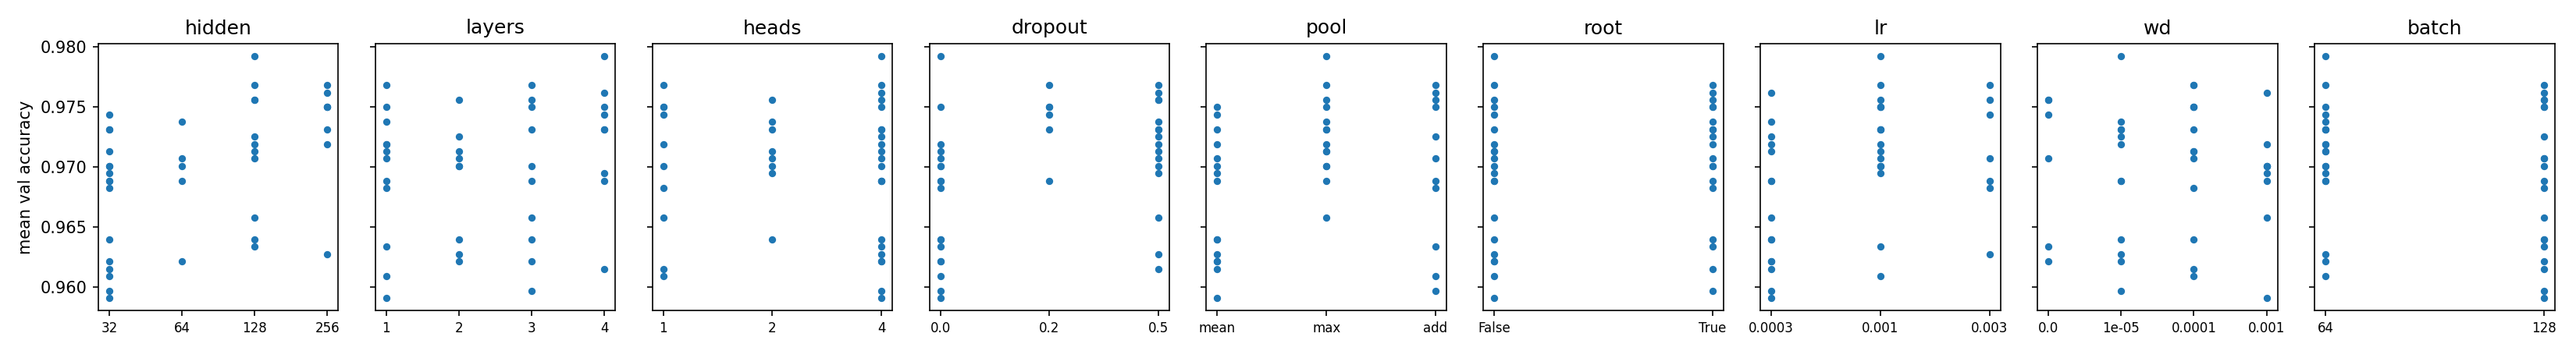

In [16]:
import matplotlib.pyplot as plt
search = search.sort_values('val', ascending=False)
print(search.head(10).round(4).to_string())
best = trials[search.index[0]]
print("\nbest:", best)
fig, ax = plt.subplots(1, len(space), figsize=(22, 3), sharey=True)
for a, k in zip(ax, space):
    a.scatter(search[k].map(space[k].index), search.val, s=12)
    a.set_xticks(range(len(space[k])), [str(v) for v in space[k]], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("mean val accuracy")
plt.tight_layout(); plt.savefig('gt_search.png', dpi=150); plt.show()

## 17. Test the tuned GPS model on ten fresh seeds

The search used seeds 0 to 2. We retrain the chosen configuration on ten new seeds and score each run once on the 3,826 test graphs. The spread over seeds shows how much of any difference is noise.

In [17]:
runs = [fit(best, s) for s in final_seeds]
P = np.stack([predict(m, test_b) for m, _ in runs])
tuned = pd.DataFrame([scores(y_test, p) for p in P])
print(pd.DataFrame({'baseline': base.mean(), 'baseline std': base.std(), 'tuned': tuned.mean(), 'tuned std': tuned.std()}).round(4))

     baseline  baseline std   tuned  tuned std
acc    0.9686        0.0056  0.9777     0.0027
f1     0.9686        0.0056  0.9777     0.0027
auc    0.9892        0.0012  0.9915     0.0016


## 18. The model we analyse

The analyses that need a single model use the run with the highest validation accuracy among the ten. Picking the highest test accuracy instead would be peeking at the test set.

Its confusion matrix shows whether the errors fall mostly on one class.

seed 106   val acc = 0.9835   test: {'acc': 0.9754, 'f1': 0.9754, 'auc': np.float64(0.9913)}


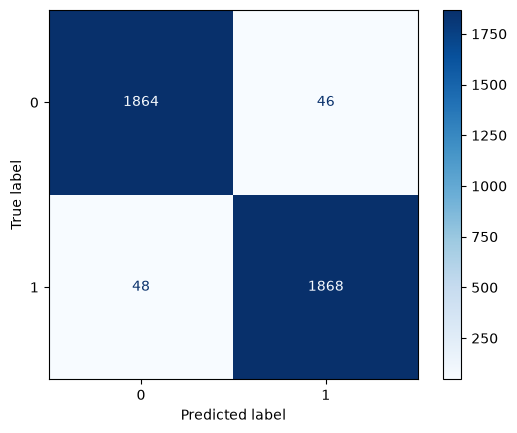

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
k = int(np.argmax([v for _, v in runs]))
model, p_best = runs[k][0], P[k]
print("seed", final_seeds[k], "  val acc =", round(runs[k][1], 4), "  test:", {m: round(v, 4) for m, v in scores(y_test, p_best).items()})
ConfusionMatrixDisplay(confusion_matrix(y_test, p_best > .5)).plot(cmap='Blues'); plt.show()

## 19. Ablation: which parts of the input does the model need?

An ablation removes one ingredient and retrains with the same tuned hyperparameters on the five seeds in `abl_seeds`. Train, validation and test graphs are changed in the same way, and the positional encodings are recomputed on the changed graphs, because they are a function of the edges.

- **No edges ($\tilde A=I$).** The GIN branch sees only the node itself and every encoding becomes $0$, so the model is a transformer on an unordered set of users.
- **Constant features.** Every $x_v$ becomes a vector of ones, so only the shape of the cascade, through the edges and the encodings, is left.
- **Random tree.** The users stay but are re-attached at random: node $i$ gets a parent drawn uniformly from $0,\ldots,i-1$. The size is kept; who-retweeted-whom is lost.
- **Text only / profile only.** One of the two feature blocks is set to zero.
- **News node only.** Every user is deleted and only the root remains. This asks whether the cascade adds anything to the article itself.
- **Directed edges.** We skip `ToUndirected()`. Messages flow only from parent to child and, as shown when we built them, every encoding is $0$. Attention does not use the edges, so it is unaffected.

In [19]:
from torch_geometric.utils import to_undirected

def no_edges(g): g.edge_index = g.edge_index[:, :0]; return g
def ones(g):     g.x = torch.ones_like(g.x); return g
def text(g):     g.x[:, 300:] = 0; return g
def profile(g):  g.x[:, :300] = 0; return g
def news(g):     g.x, g.edge_index = g.x[:1], g.edge_index[:, :0]; return g
def rand_tree(g):
    child = torch.arange(1, g.num_nodes)
    g.edge_index = to_undirected(torch.stack([(torch.rand(len(child)) * child).long(), child]))
    return g

def variant(f):
    return ([add_pe(f(g.clone())) for g in train_set], batches([add_pe(f(g.clone())) for g in val_set]),
            batches([add_pe(f(g.clone())) for g in test_set]))

def run(c, tr, va, te):
    return pd.DataFrame([scores(y_test, predict(fit(c, s, tr, va)[0], te)) for s in abl_seeds])

def table(d):
    t = pd.DataFrame({k: v.mean() for k, v in d.items()}).T
    t['acc std'] = [v.acc.std() for v in d.values()]
    t['Δ acc'] = t.acc - t.acc.iloc[0]
    return t.round(4)

torch.manual_seed(0)
abl = {'tuned GPS': tuned.iloc[:len(abl_seeds)]}
for name, f in [('no edges (A = I)', no_edges), ('constant features', ones), ('random tree', rand_tree),
                ('text features only', text), ('profile features only', profile), ('news node only', news)]:
    abl[name] = run(best, *variant(f))
abl['directed edges'] = run(best, [add_pe(g) for g in raw['train']], batches([add_pe(g) for g in raw['val']]), batches([add_pe(g) for g in raw['test']]))
print(table(abl))

                          acc      f1     auc  acc std   Δ acc
tuned GPS              0.9782  0.9782  0.9915   0.0026  0.0000
no edges (A = I)       0.9769  0.9769  0.9934   0.0030 -0.0013
constant features      0.8159  0.8154  0.8907   0.0079 -0.1623
random tree            0.9761  0.9761  0.9930   0.0019 -0.0021
text features only     0.9724  0.9724  0.9881   0.0045 -0.0058
profile features only  0.9544  0.9544  0.9843   0.0059 -0.0238
news node only         0.9608  0.9608  0.9851   0.0023 -0.0174
directed edges         0.9769  0.9769  0.9930   0.0027 -0.0013


## 20. Ablation: which parts of the GPS layer matter?

Now the data stays fixed and we change one part of the tuned model at a time:

- **attention only**: no GIN branch, a plain transformer that sees the graph only through the encodings,
- **GIN only**: no attention branch, a pure message-passing network,
- **no positional encoding**,
- the other two readouts, and the root-feature shortcut switched the other way.

The first two show what each half of the GPS layer contributes, and the third shows whether attention needs to be told where nodes are.

In [20]:
arch = {'tuned GPS': tuned.iloc[:len(abl_seeds)]}
changes = [('attention only (no GIN)', dict(local=False)), ('GIN only (no attention)', dict(attn=False)), ('no positional encoding', dict(pe=False))]
changes += [(f'{p} readout', dict(pool=p)) for p in space['pool'] if p != best['pool']]
changes += [(f"root features = {not best['root']}", dict(root=not best['root']))]
for name, ch in changes:
    arch[name] = run(dict(best, **ch), train_set, val_b, test_b)
print(table(arch))

                            acc      f1     auc  acc std   Δ acc
tuned GPS                0.9782  0.9782  0.9915   0.0026  0.0000
attention only (no GIN)  0.9788  0.9788  0.9950   0.0012  0.0006
GIN only (no attention)  0.9605  0.9605  0.9858   0.0069 -0.0177
no positional encoding   0.9766  0.9766  0.9909   0.0026 -0.0016
mean readout             0.9794  0.9794  0.9926   0.0028  0.0012
add readout              0.9754  0.9754  0.9872   0.0044 -0.0028
root features = True     0.9779  0.9779  0.9905   0.0025 -0.0003


## 21. Ablation: depth

A GCN over-smooths as layers are added: repeated neighbourhood averaging pulls all node embeddings of a graph towards the same vector. Attention can also collapse to near-uniform weights, which has the same effect, so we test depth the same way as for the GCN: 1, 2, 4 and 8 layers, with and without the root shortcut.

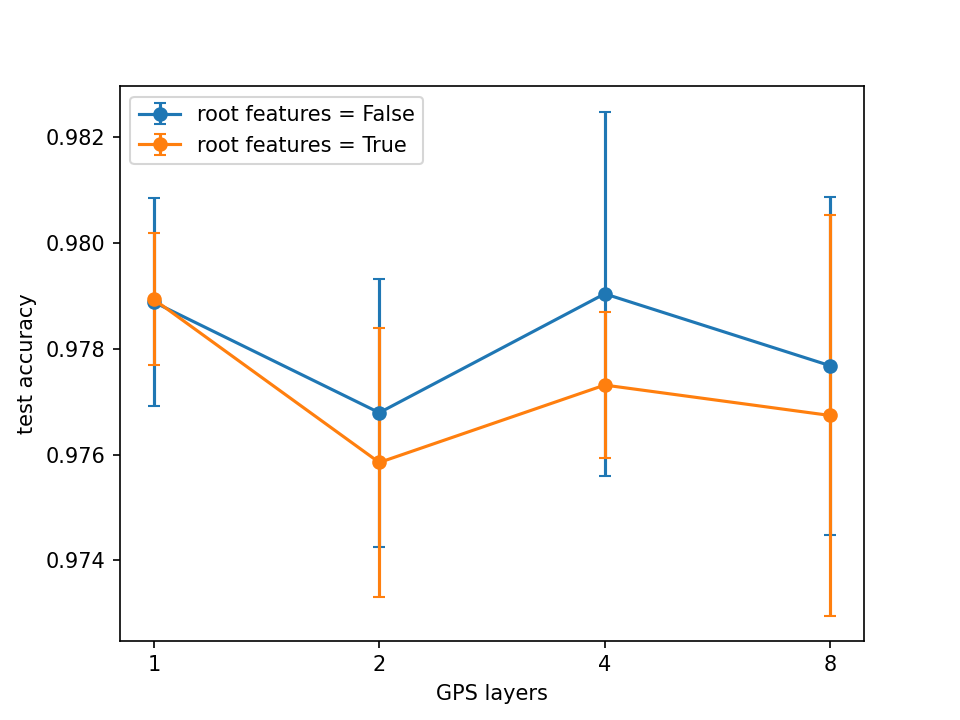

In [21]:
Ls = [1, 2, 4, 8]
depth = {(r, L): run(dict(best, root=r, layers=L), train_set, val_b, test_b) for r in [False, True] for L in Ls}
for r in [False, True]:
    plt.errorbar(Ls, [depth[r, L].acc.mean() for L in Ls], [depth[r, L].acc.std() for L in Ls], marker='o', capsize=3, label=f'root features = {r}')
plt.xscale('log', base=2); plt.xticks(Ls, Ls)
plt.xlabel("GPS layers"); plt.ylabel("test accuracy"); plt.legend()
plt.savefig('gt_depth.png', dpi=150); plt.show()

## 22. Visualisation: t-SNE of graph embeddings

`embed` returns the vector the classifier sees, one per graph. t-SNE maps these vectors to 2D while keeping near neighbours near.

On the left is the input itself, the mean of each graph's raw node features. On the right is the tuned model's embedding. Colour is the true class, and crosses are graphs the model gets wrong.

The silhouette score, computed in the original space and not in 2D, measures class separation on a scale from $-1$ to $1$.

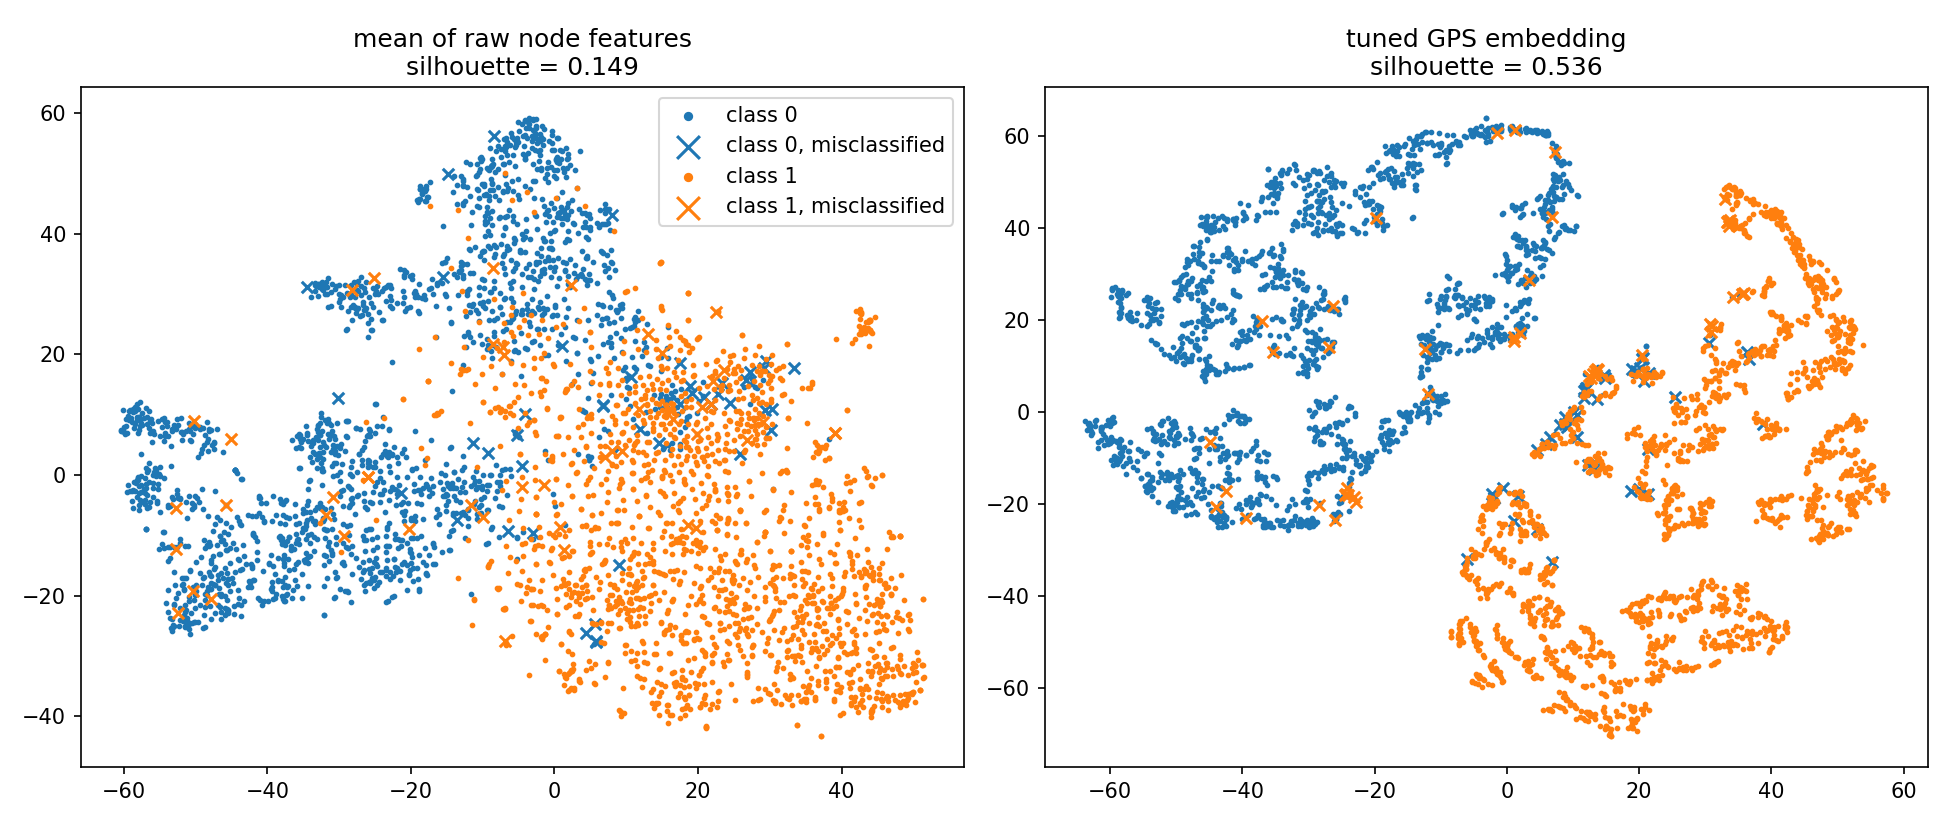

In [22]:
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed_all(model, bs):
    model.eval()
    return torch.cat([model.embed(b.x, b.edge_index, b.pe, b.batch) for b in bs]).cpu().numpy()

Z = {'mean of raw node features': torch.cat([global_mean_pool(b.x, b.batch) for b in test_b]).cpu().numpy(),
     'tuned GPS embedding': embed_all(model, test_b)}
wrong = (p_best > .5) != y_test
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, (name, E) in zip(ax, Z.items()):
    T2 = TSNE(2, init='pca', random_state=0).fit_transform(E)
    for c, col in [(0, 'tab:blue'), (1, 'tab:orange')]:
        a.scatter(*T2[(y_test == c) & ~wrong].T, s=3, c=col, label=f'class {c}')
        a.scatter(*T2[(y_test == c) & wrong].T, s=30, c=col, marker='x', label=f'class {c}, misclassified')
    a.set_title(f"{name}\nsilhouette = {silhouette_score(E, y_test):.3f}")
ax[0].legend(markerscale=2)
plt.tight_layout(); plt.savefig('gt_tsne.png', dpi=150); plt.show()

## 23. Efficiency: the cost of one model

For the tuned model we measure

- the number of trainable parameters,
- the wall-clock time of one training epoch, averaged over ten epochs after one warm-up epoch,
- the peak GPU memory during training, above what the stored validation and test batches already take,
- the time to score all 3,826 test graphs, and the median latency of one graph at batch size 1.

Attention compares every pair of nodes in a graph, so its cost grows with $|V|^2$ instead of $|E|$. On the GPU, `synchronize()` makes the timer wait until the kernels have finished.

In [23]:
sync = torch.cuda.synchronize if device == 'cuda' else (lambda: None)
one_b = batches(test_set[:200], size=1)

def cost(c, n=10):
    seed_everything(0)
    model = Net(**c).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=c['lr'], weight_decay=c['wd'])
    loader = DataLoader(train_set, batch_size=c['batch'], shuffle=True)
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats(); m0 = torch.cuda.memory_allocated()
    times = []
    for epoch in range(n + 1):
        sync(); t = time.time()
        model.train()
        for b in loader:
            b = b.to(device)
            opt.zero_grad()
            F.cross_entropy(model(b.x, b.edge_index, b.pe, b.batch), b.y).backward()
            opt.step()
        sync(); times.append(time.time() - t)
    peak = (torch.cuda.max_memory_allocated() - m0) / 2**20 if device == 'cuda' else float('nan')
    sync(); t = time.time(); predict(model, test_b); sync(); full = time.time() - t
    lat = []
    for b in one_b:
        sync(); t = time.time(); predict(model, [b]); sync(); lat.append(time.time() - t)
    return dict(params=sum(p.numel() for p in model.parameters()), epoch_s=np.mean(times[1:]),
                peak_train_mb=peak, test_set_s=full, one_graph_ms=1000 * np.median(lat))

eff = cost(best)
for k, v in eff.items():
    print(f"{k:14s} {v:.4g}")

params         7.172e+05
epoch_s        0.7557
peak_train_mb  275.4
test_set_s     0.6579
one_graph_ms   8.42


## 24. Accuracy against model size

Width drives the parameter count. We vary the hidden size of the tuned configuration from 16 to 512, train three seeds at each width, and plot test accuracy against parameters, next to the time per epoch.

   hidden     acc  acc_std    params  epoch_s  peak_train_mb  test_set_s  one_graph_ms
0      16  0.9682   0.0010     14082   0.5592        53.8340      0.3544        8.2791
1      32  0.9671   0.0065     51554   0.5598        88.6104      0.3883        8.1021
2      64  0.9745   0.0027    189474   0.6125       150.4614      0.4754        8.8555
3     128  0.9764   0.0013    717218   0.7647       275.4238      0.6703        8.4571
4     256  0.9747   0.0045   2780322   1.3439       516.1567      1.3365        8.7913
5     512  0.9756   0.0013  10936994   3.4086      1070.9785      3.5366        8.9278


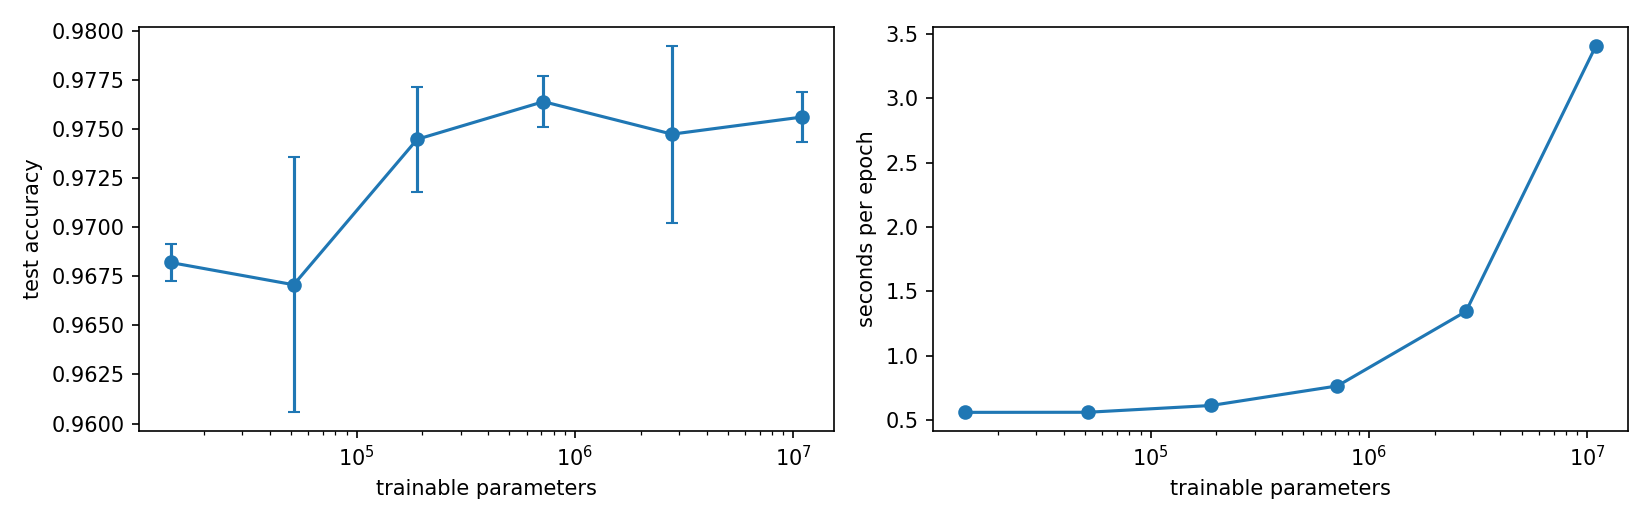

In [24]:
size_rows = []
for h in [16, 32, 64, 128, 256, 512]:
    c = dict(best, hidden=h)
    acc = [scores(y_test, predict(fit(c, s)[0], test_b))['acc'] for s in abl_seeds[:3]]
    size_rows.append(dict(hidden=h, acc=np.mean(acc), acc_std=np.std(acc), **cost(c)))
sizes = pd.DataFrame(size_rows)
print(sizes.round(4).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(sizes.params, sizes.acc, sizes.acc_std, marker='o', capsize=3)
ax[1].plot(sizes.params, sizes.epoch_s, marker='o')
for a, lab in zip(ax, ["test accuracy", "seconds per epoch"]):
    a.set_xscale('log'); a.set_xlabel("trainable parameters"); a.set_ylabel(lab)
plt.tight_layout(); plt.savefig('gt_size.png', dpi=150); plt.show()

## 25. Robustness: missing edges and noisy features

We perturb only the test graphs and re-score the ten tuned runs, which were trained on clean data.

- **Edge removal.** Each undirected edge is removed with probability $p$, for $p$ from $0$ to $0.5$. Both directions go together, and the positional encodings are recomputed on the damaged graph.
- **Feature noise.** We add $\sigma\, s_j\,\varepsilon$ to feature $j$ of every node, where $s_j$ is the standard deviation of feature $j$ over the training nodes and $\varepsilon\sim\mathcal N(0,1)$.

Each perturbed test set is drawn once and shared by the ten runs.

In [25]:
from torch_geometric.utils import dropout_edge
sd = X.std(0)

def perturbed(p=0.0, sigma=0.0):
    out = []
    for g in test_set:
        g = g.clone()
        g.edge_index = dropout_edge(g.edge_index, p=p, force_undirected=True)[0]
        g.x = g.x + sigma * sd * torch.randn_like(g.x)
        out.append(add_pe(g))
    return batches(out)

torch.manual_seed(0)
drop, noise = {}, {}
for p in [0, .1, .2, .3, .4, .5]:
    bs = perturbed(p=p)
    drop[p] = [scores(y_test, predict(m, bs))['acc'] for m, _ in runs]
for s in [0, .1, .25, .5, 1, 2]:
    bs = perturbed(sigma=s)
    noise[s] = [scores(y_test, predict(m, bs))['acc'] for m, _ in runs]

## 26. Robustness: scarce labels

The other kind of imperfect data is having few labels. We train on a stratified fraction of the 1,092 training graphs, from 5% (54 graphs) up to all of them, and keep the full validation split for early stopping.

In [26]:
from sklearn.model_selection import train_test_split
labels = {}
for f in [.05, .1, .25, .5, 1.0]:
    accs = []
    for s in abl_seeds:
        idx = np.arange(len(train_set)) if f == 1 else train_test_split(np.arange(len(train_set)), train_size=f, stratify=y_train, random_state=s)[0]
        accs.append(scores(y_test, predict(fit(best, s, [train_set[i] for i in idx])[0], test_b))['acc'])
    labels[f] = accs

## 27. Robustness curves

Each point is the mean test accuracy over runs; the error bar is one standard deviation.

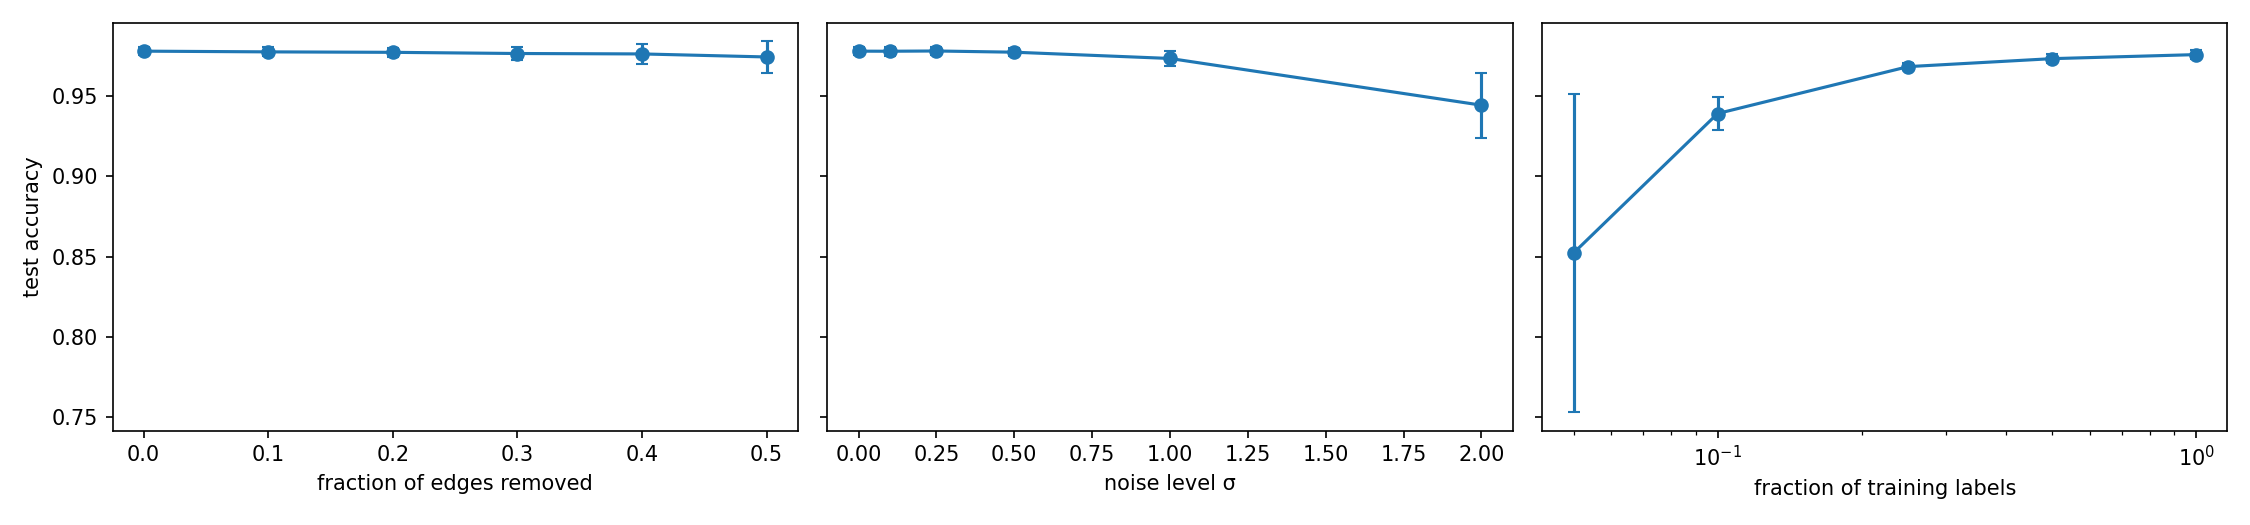

edge removal {0: np.float64(0.9777), 0.1: np.float64(0.9773), 0.2: np.float64(0.977), 0.3: np.float64(0.9763), 0.4: np.float64(0.976), 0.5: np.float64(0.9741)}
feature noise {0: np.float64(0.9777), 0.1: np.float64(0.9777), 0.25: np.float64(0.9778), 0.5: np.float64(0.9771), 1: np.float64(0.9732), 2: np.float64(0.9441)}
label fraction {0.05: np.float64(0.8522), 0.1: np.float64(0.9389), 0.25: np.float64(0.9681), 0.5: np.float64(0.9731), 1.0: np.float64(0.9756)}


In [27]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, (d, lab) in zip(ax, [(drop, "fraction of edges removed"), (noise, "noise level σ"), (labels, "fraction of training labels")]):
    a.errorbar(list(d), [np.mean(v) for v in d.values()], [np.std(v) for v in d.values()], marker='o', capsize=3)
    a.set_xlabel(lab)
ax[2].set_xscale('log'); ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gt_robustness.png', dpi=150); plt.show()
for name, d in [('edge removal', drop), ('feature noise', noise), ('label fraction', labels)]:
    print(name, {k: round(np.mean(v), 4) for k, v in d.items()})

## 28. Error analysis by cascade topology

The brief's examples are about nodes, such as accuracy by node degree. For graph classification we instead describe each cascade by its shape and ask whether the model fails more often on some shapes:

- **nodes**, the size $|V|$,
- **depth**, the longest path from the root to a leaf,
- **root degree**, how many users shared the news directly; the root is the hub of the cascade,
- **star share**, root degree divided by $|V|-1$: $1$ for a pure star, small for long chains.

Correctness of each test graph is averaged over the ten tuned runs, which smooths out seed noise.

In [28]:
import networkx as nx
from torch_geometric.utils import to_networkx

def shape(g):
    G = to_networkx(g, to_undirected=True)
    hops = nx.single_source_shortest_path_length(G, 0)
    return dict(nodes=g.num_nodes, depth=max(hops.values()), root_degree=G.degree(0), star_share=G.degree(0) / max(g.num_nodes - 1, 1))

T = pd.DataFrame([shape(g) for g in raw['test']])
T['y'] = y_test
C = (P > .5) == y_test
T['correct'] = C.mean(0)
print(T.groupby('y')[['nodes', 'depth', 'root_degree', 'star_share']].median())

   nodes  depth  root_degree  star_share
y                                       
0   69.5    2.0         58.0    0.925373
1   23.0    2.0         15.0    0.789474


## 29. Accuracy by quartile of each property

Each property is cut into quartiles over the test set, with fewer bins when many graphs share the same value. In every bin we compute accuracy for each of the ten runs and plot the mean with one standard deviation. The label under a bin gives the number of graphs in it.

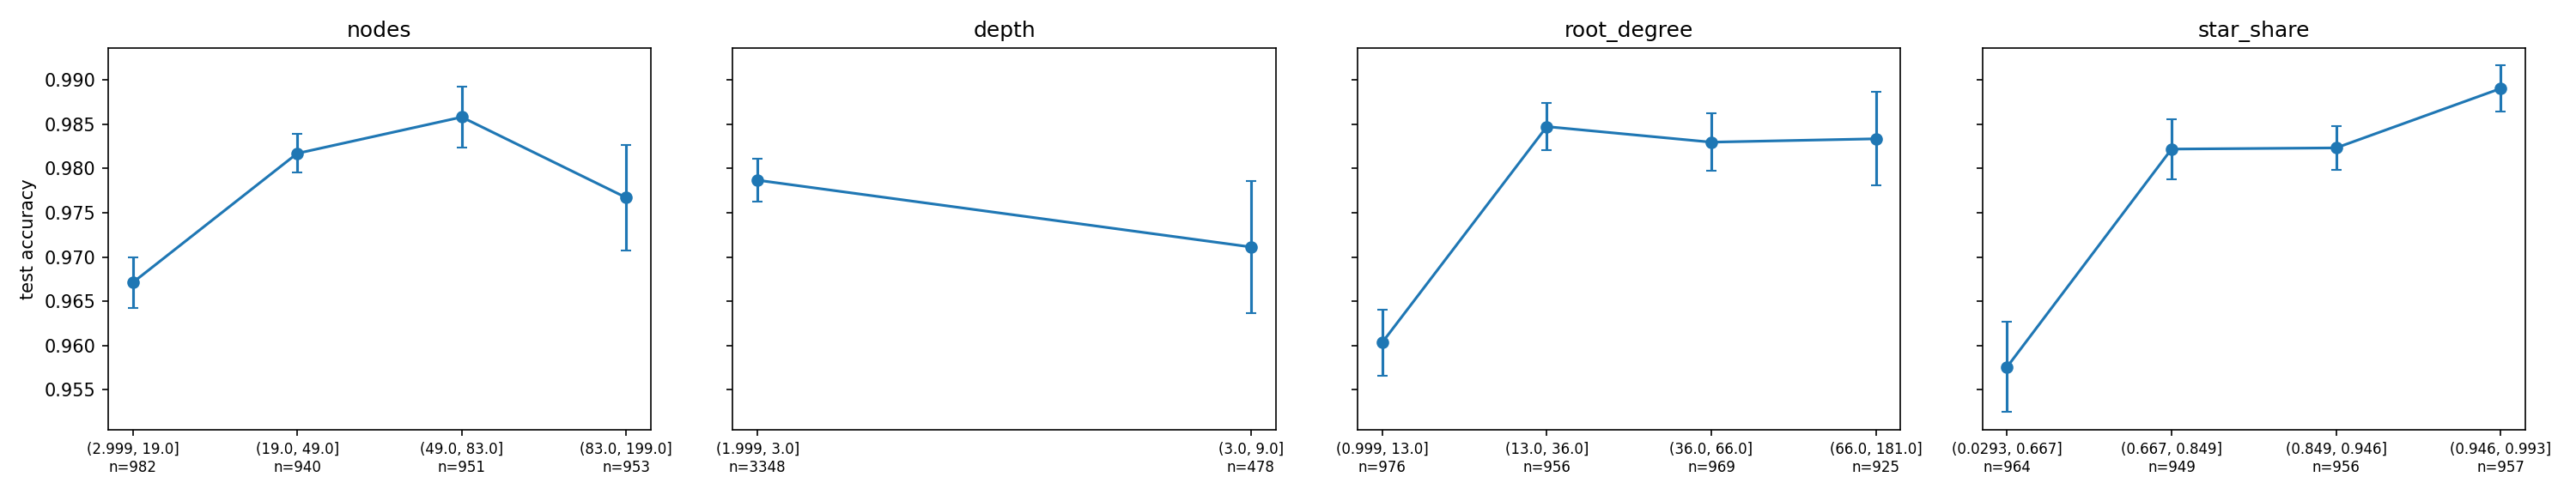

In [29]:
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8), sharey=True)
for a, k in zip(ax, ['nodes', 'depth', 'root_degree', 'star_share']):
    q = pd.qcut(T[k], 4, duplicates='drop')
    acc = pd.DataFrame(C.T).groupby(q.values, observed=True).mean()
    a.errorbar(range(len(acc)), acc.mean(axis=1), acc.std(axis=1), marker='o', capsize=3)
    a.set_xticks(range(len(acc)), [f"{i}\nn={(q == i).sum()}" for i in acc.index], fontsize=8)
    a.set_title(k)
ax[0].set_ylabel("test accuracy")
plt.tight_layout(); plt.savefig('gt_topology.png', dpi=150); plt.show()

## 30. Shape or class?

A property can look linked to errors only because it differs between the two classes. Splitting the size quartiles by class separates the two effects.

We also count the graphs that every run gets wrong. These are the consistently hard cases, not seed noise.

In [30]:
q = pd.qcut(T.nodes, 4)
print(T.groupby([q, 'y'], observed=True).correct.agg(['mean', 'size']).unstack().round(3))
print("\nmisclassified by all ten runs:", (T.correct == 0).sum(), "   by none:", (T.correct == 1).sum(), "   of", len(T))

                mean        size     
y                  0      1    0    1
nodes                                
(2.999, 19.0]  0.756  0.992  104  878
(19.0, 49.0]   0.975  0.986  392  548
(49.0, 83.0]   0.992  0.968  721  230
(83.0, 199.0]  0.989  0.943  693  260

misclassified by all ten runs: 40    by none: 3621    of 3826


## 31. Explainability: masking feature groups

The simplest explanation method is occlusion: hide part of the input and see how far the model's confidence in its own prediction falls. On every test graph we

- zero the text block (columns 0 to 299) or the profile block (300 to 309) of every node,
- zero the news node's features only, or every user's features while keeping the news node,
- shuffle the users' feature rows across the batch, which keeps the feature distribution but breaks which user sits where.

The positional encodings are left as they are, since the structure does not change. We report test accuracy, the mean drop in confidence of the original prediction, and the share of predictions that flip.

In [31]:
def users(b):
    m = torch.ones(b.num_nodes, dtype=torch.bool, device=b.x.device); m[b.ptr[:-1]] = False
    return m

def zero_text(b):    b.x[:, :300] = 0
def zero_profile(b): b.x[:, 300:] = 0
def zero_news(b):    b.x[b.ptr[:-1]] = 0
def zero_users(b):   b.x[users(b)] = 0
def shuffle_users(b):
    u = users(b).nonzero().view(-1)
    b.x[u] = b.x[u[torch.randperm(len(u), device=u.device)]]

def occlude(f):
    bs = [b.clone() for b in test_b]
    for b in bs:
        f(b)
    p = predict(model, bs)
    c0 = np.where(p_best > .5, p_best, 1 - p_best)
    c1 = np.where(p_best > .5, p, 1 - p)
    return dict(acc=scores(y_test, p)['acc'], confidence_drop=(c0 - c1).mean(), flipped=((p > .5) != (p_best > .5)).mean())

torch.manual_seed(0)
occl = pd.DataFrame({name: occlude(f) for name, f in [('nothing', lambda b: None), ('text block', zero_text), ('profile block', zero_profile),
                     ('news node', zero_news), ('all users', zero_users), ('shuffle users', shuffle_users)]}).T
print(occl.round(4))

                  acc  confidence_drop  flipped
nothing        0.9754           0.0000   0.0000
text block     0.5008           0.5088   0.4997
profile block  0.9739           0.0245   0.0110
news node      0.4992           0.4272   0.5003
all users      0.4969           0.5135   0.5063
shuffle users  0.5277           0.4396   0.4692


## 32. Explainability: four standard attribution methods

Occlusion tells us which feature groups matter on average. Attribution methods explain one graph at a time: they score every node feature and every edge by how much it pushed the model towards its prediction.

- **GNNExplainer** (Ying et al., 2019) learns a soft mask over edges and features that keeps the prediction while staying small.
- **PGExplainer** (Luo et al., 2020) trains one small network that predicts an edge mask from the two end-point embeddings, so it explains any graph without re-optimising. It scores edges only.
- **Saliency** is the absolute gradient of the predicted logit with respect to each input.
- **Integrated Gradients** (Sundararajan et al., 2017) integrates that gradient along a straight path from an all-zero input to the real one.

The last two come from Captum through PyG's `CaptumExplainer`. PGExplainer is first trained on 200 training graphs.

An edge mask can only act on the GIN branch. Attention never reads the edge list, so masking an edge cannot switch it off. That is why a later section, *where does attention look?*, reads the attention weights directly.

GNNExplainer works on its own copy of the model. It stores its edge mask as a parameter inside the message-passing layers, and in PyG 2.8 that silently cuts the other methods' edge masks off from the gradient.

In [32]:
from torch_geometric.explain import Explainer, GNNExplainer, PGExplainer, CaptumExplainer
cfg = dict(mode='multiclass_classification', task_level='graph', return_type='raw')
model.eval()
explainers = {
    'GNNExplainer': Explainer(copy.deepcopy(model), GNNExplainer(epochs=200), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
    'PGExplainer': Explainer(model, PGExplainer(epochs=30, lr=0.003).to(device), 'phenomenon', cfg, edge_mask_type='object'),
    'Saliency': Explainer(model, CaptumExplainer('Saliency'), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
    'Integrated Gradients': Explainer(model, CaptumExplainer('IntegratedGradients'), 'model', cfg, node_mask_type='attributes', edge_mask_type='object'),
}
random.seed(0)
pg_train = [g.clone().to(device) for g in random.sample(train_set, 200)]
for epoch in range(30):
    for g in pg_train:
        explainers['PGExplainer'].algorithm.train(epoch, model, g.x, g.edge_index, target=g.y, pe=g.pe)

## 33. Explain test graphs

We explain `n_explain` test graphs, half from each class. GNNExplainer, Saliency and Integrated Gradients explain the model's own prediction. PGExplainer, being a phenomenon explainer, explains the true label.

For every graph we keep the node-feature mask ($|V|\times310$) and the edge mask ($|E|$), and we time each method.

In [33]:
rng = np.random.RandomState(0)
idx = np.concatenate([rng.choice(np.where(y_test == c)[0], n_explain // 2, replace=False) for c in [0, 1]])
E, secs = {name: [] for name in explainers}, {name: 0.0 for name in explainers}
for i in idx:
    g = test_set[i].clone().to(device)
    for name, ex in explainers.items():
        t = time.time()
        e = ex(g.x, g.edge_index, target=g.y, pe=g.pe) if name == 'PGExplainer' else ex(g.x, g.edge_index, pe=g.pe)
        secs[name] += (time.time() - t) / len(idx)
        E[name].append((e.node_mask.detach().cpu() if 'node_mask' in e else None, e.edge_mask.detach().cpu()))
print({k: f"{v:.3f} s/graph" for k, v in secs.items()})

{'GNNExplainer': '4.117 s/graph', 'PGExplainer': '0.010 s/graph', 'Saliency': '0.027 s/graph', 'Integrated Gradients': '0.893 s/graph'}


## 34. Are the explanations faithful?

A faithful explanation points at inputs the model really uses. We test this with fidelity (Amara et al., 2022): remove the top $k$ fraction of nodes or edges by importance and measure how far the probability of the predicted class falls,

$\text{Fid}^+ = P(\hat y\mid G) - P(\hat y\mid G\setminus G_k)$

A node is removed by zeroing its features; an edge by deleting both of its directions, after which the positional encodings are recomputed. A method is only useful if it beats a random ranking, which we add as a baseline.

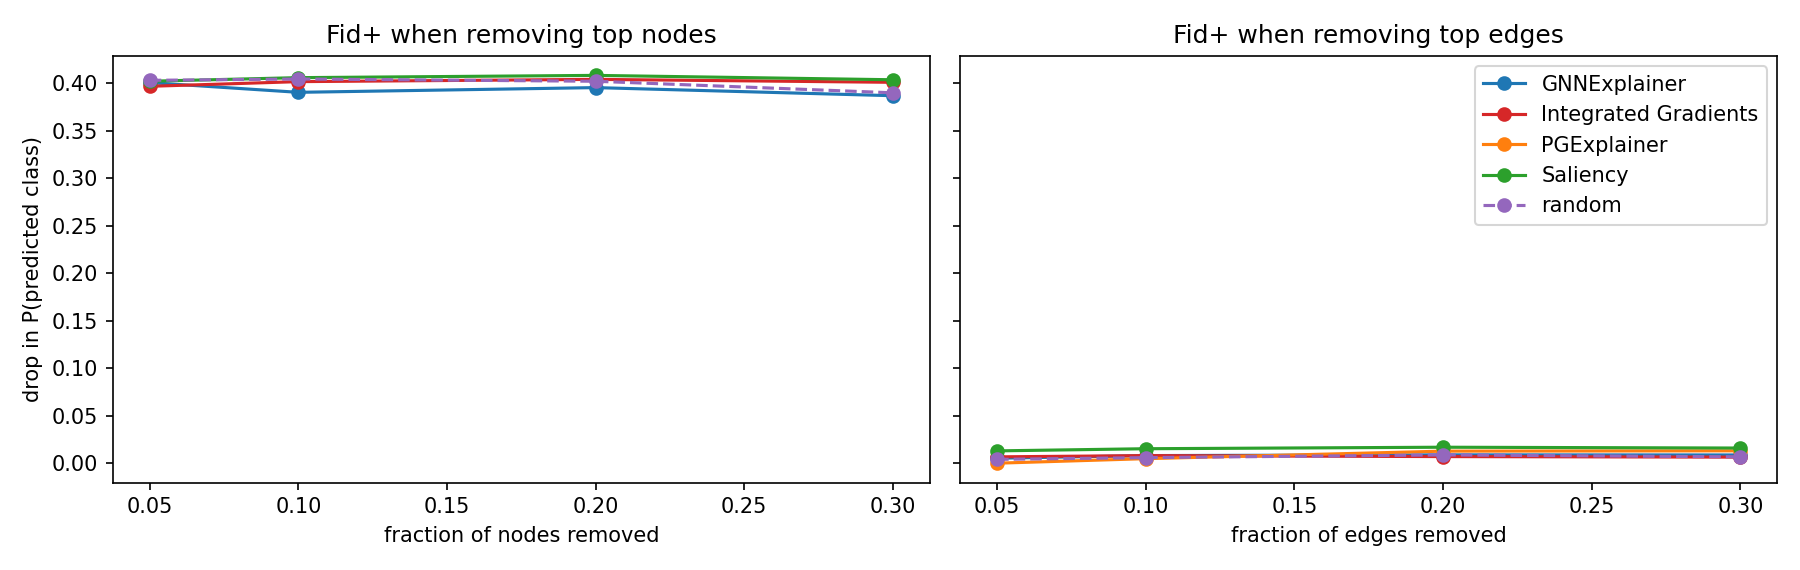

In [34]:
from torch_geometric.data import Data

@torch.no_grad()
def conf(x, ei, c):
    pe = add_pe(Data(edge_index=ei.cpu(), num_nodes=x.size(0))).pe.to(device)
    return model(x, ei, pe).softmax(1)[0, c].item()

def fid_nodes(g, score, k, c):
    x = g.x.clone()
    x[score.argsort(descending=True)[:max(1, int(k * g.num_nodes))]] = 0
    return conf(g.x, g.edge_index, c) - conf(x, g.edge_index, c)

def fid_edges(g, score, k, c):
    ei, w = to_undirected(g.edge_index, score, reduce='mean')
    pairs, w = ei[:, ei[0] < ei[1]], w[ei[0] < ei[1]]
    keep = torch.ones(pairs.size(1), dtype=torch.bool, device=pairs.device)
    keep[w.argsort(descending=True)[:max(1, int(k * pairs.size(1)))]] = False
    return conf(g.x, g.edge_index, c) - conf(g.x, to_undirected(pairs[:, keep]), c)

torch.manual_seed(0)
ks, rows = [.05, .1, .2, .3], []
for j, i in enumerate(idx):
    g, c = test_set[i].clone().to(device), int(p_best[i] > .5)
    for name in list(E) + ['random']:
        nm, em = E[name][j] if name != 'random' else (torch.rand(g.num_nodes, 1), torch.rand(g.num_edges))
        for k in ks:
            rows.append(dict(method=name, k=k, edges=fid_edges(g, em.to(device), k, c),
                             nodes=fid_nodes(g, nm.abs().sum(1).to(device), k, c) if nm is not None else np.nan))
fid = pd.DataFrame(rows).groupby(['method', 'k']).mean()
colors = dict(zip(list(E) + ['random'], plt.rcParams['axes.prop_cycle'].by_key()['color']))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, col in zip(ax, ['nodes', 'edges']):
    for name, d in fid[col].unstack('k').iterrows():
        if not d.isna().all():
            a.plot(ks, d.values, marker='o', label=name, color=colors[name], ls='--' if name == 'random' else '-')
    a.set_xlabel(f"fraction of {col} removed"); a.set_title(f"Fid+ when removing top {col}")
ax[0].set_ylabel("drop in P(predicted class)"); ax[1].legend()
plt.tight_layout(); plt.savefig('gt_fidelity.png', dpi=150); plt.show()

## 35. What the explanations point at

Two summaries over the explained graphs, for the three methods that score node features:

- **Feature blocks.** The mean absolute attribution per column, in the text block and in the profile block. Taking a per-column mean makes the 300-column and the 10-column block comparable.
- **The news node.** The share of a graph's total node importance that lands on the root, against $1/|V|$, the share it would get if all nodes mattered equally.

In [35]:
rows = []
for name, ex in E.items():
    if ex[0][0] is None:
        continue
    M = torch.cat([nm.abs() for nm, _ in ex])
    share = [(nm.abs().sum(1)[0] / nm.abs().sum()).item() for nm, _ in ex if nm.abs().sum() > 0]
    rows.append(dict(method=name, text_per_column=M[:, :300].mean().item(), profile_per_column=M[:, 300:].mean().item(), news_node_share=np.mean(share)))
focus = pd.DataFrame(rows).set_index('method')
print(focus.round(4))
print("\nnews-node share if every node were equally important:", round(np.mean([1 / test_set[i].num_nodes for i in idx]), 4))

                      text_per_column  profile_per_column  news_node_share
method                                                                    
GNNExplainer                   0.3857              0.1876           0.0398
Saliency                       0.0237              0.0359           0.0375
Integrated Gradients           0.0062              0.0022           0.0504

news-node share if every node were equally important: 0.0365


## 36. Explainability: where does attention look?

The transformer's own explanation is its attention matrix. In layer $l$, row $i$ of $W^{(l)}$ says how node $i$ spreads its attention over all nodes of the cascade, averaged over heads. We read it with a hook that re-runs each layer's attention on that layer's input.

For the explained graphs we compare attention with distance in the cascade. For each hop distance $d$ we take the mean weight $W_{ij}$ over all pairs with $\text{dist}(i,j)=d$ and multiply it by $|V|$. This **lift** is $1$ when attention is uniform, above $1$ when nodes at that distance get more than their share, and below $1$ when they are ignored. We also report the lift of the news node, the attention all nodes pay to the root.

If the lift is high at $d=1$ and falls quickly, attention mostly repeats what message passing already does. If it stays near $1$ at large $d$, attention really uses its global reach.

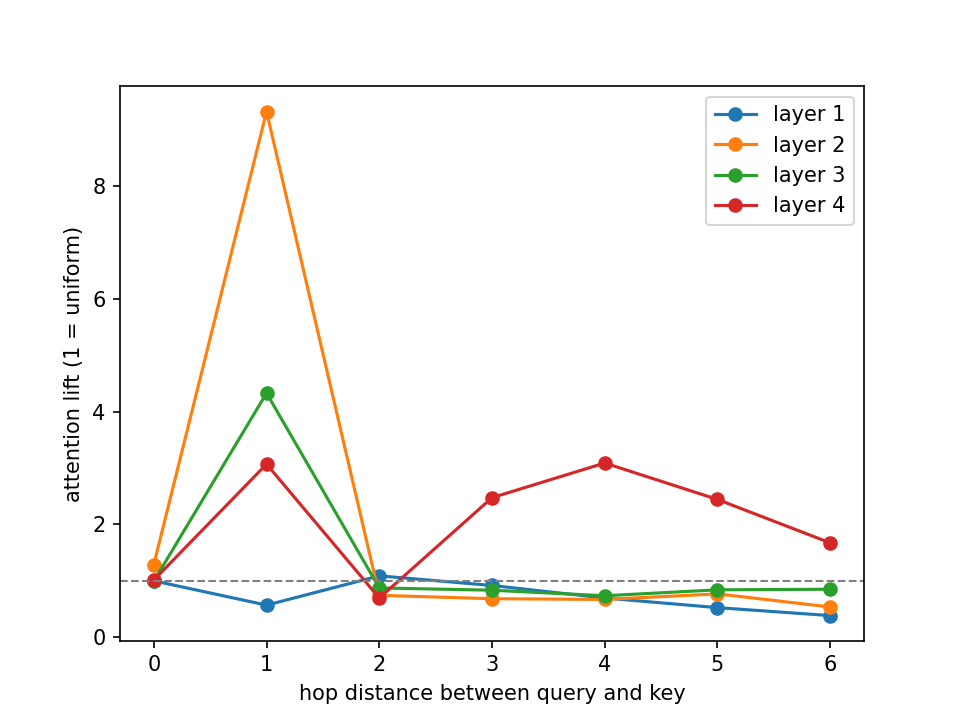

attention lift of the news node per layer: {1: np.float32(0.0), 2: np.float32(20.6), 3: np.float32(9.1), 4: np.float32(5.849)}


In [36]:
@torch.no_grad()
def attention(g):
    maps = []
    hook = lambda m, a: maps.append(m.attn(a[0][None], a[0][None], a[0][None])[1][0].cpu().numpy())
    hooks = [m.register_forward_pre_hook(hook) for m in model.modules() if isinstance(m, GPSConv)]
    model(g.x, g.edge_index, g.pe)
    for h in hooks:
        h.remove()
    return maps

lift, root_lift = {}, {}
for i in idx:
    D = nx.floyd_warshall_numpy(to_networkx(raw['test'][i], to_undirected=True))
    for l, W in enumerate(attention(test_set[i].clone().to(device))):
        n = len(W)
        root_lift.setdefault(l, []).append(W[:, 0].mean() * n)
        for d in range(min(int(D.max()), 6) + 1):
            if (D == d).any():
                lift.setdefault((l, d), []).append(W[D == d].mean() * n)
layers_seen = sorted(root_lift)
for l in layers_seen:
    ds = [d for (m, d) in lift if m == l]
    plt.plot(ds, [np.mean(lift[l, d]) for d in ds], marker='o', label=f'layer {l + 1}')
plt.axhline(1, color='grey', ls='--', lw=1)
plt.xlabel("hop distance between query and key"); plt.ylabel("attention lift (1 = uniform)"); plt.legend()
plt.savefig('gt_attention_distance.png', dpi=150); plt.show()
print("attention lift of the news node per layer:", {l + 1: round(np.mean(root_lift[l]), 3) for l in layers_seen})

## 37. Two explained cascades

From each class we draw the correctly classified explained cascade whose size is closest to 40 nodes. The news node is the large square. Node colour is the Integrated Gradients importance of the node. Edge width is the last layer's attention between the two end points, written as a lift, $|V|\,(W_{uv}+W_{vu})/2$ and capped at 4. An edge drawn at the width of lift $1$ carries exactly a uniform share of attention; thicker edges carry more.

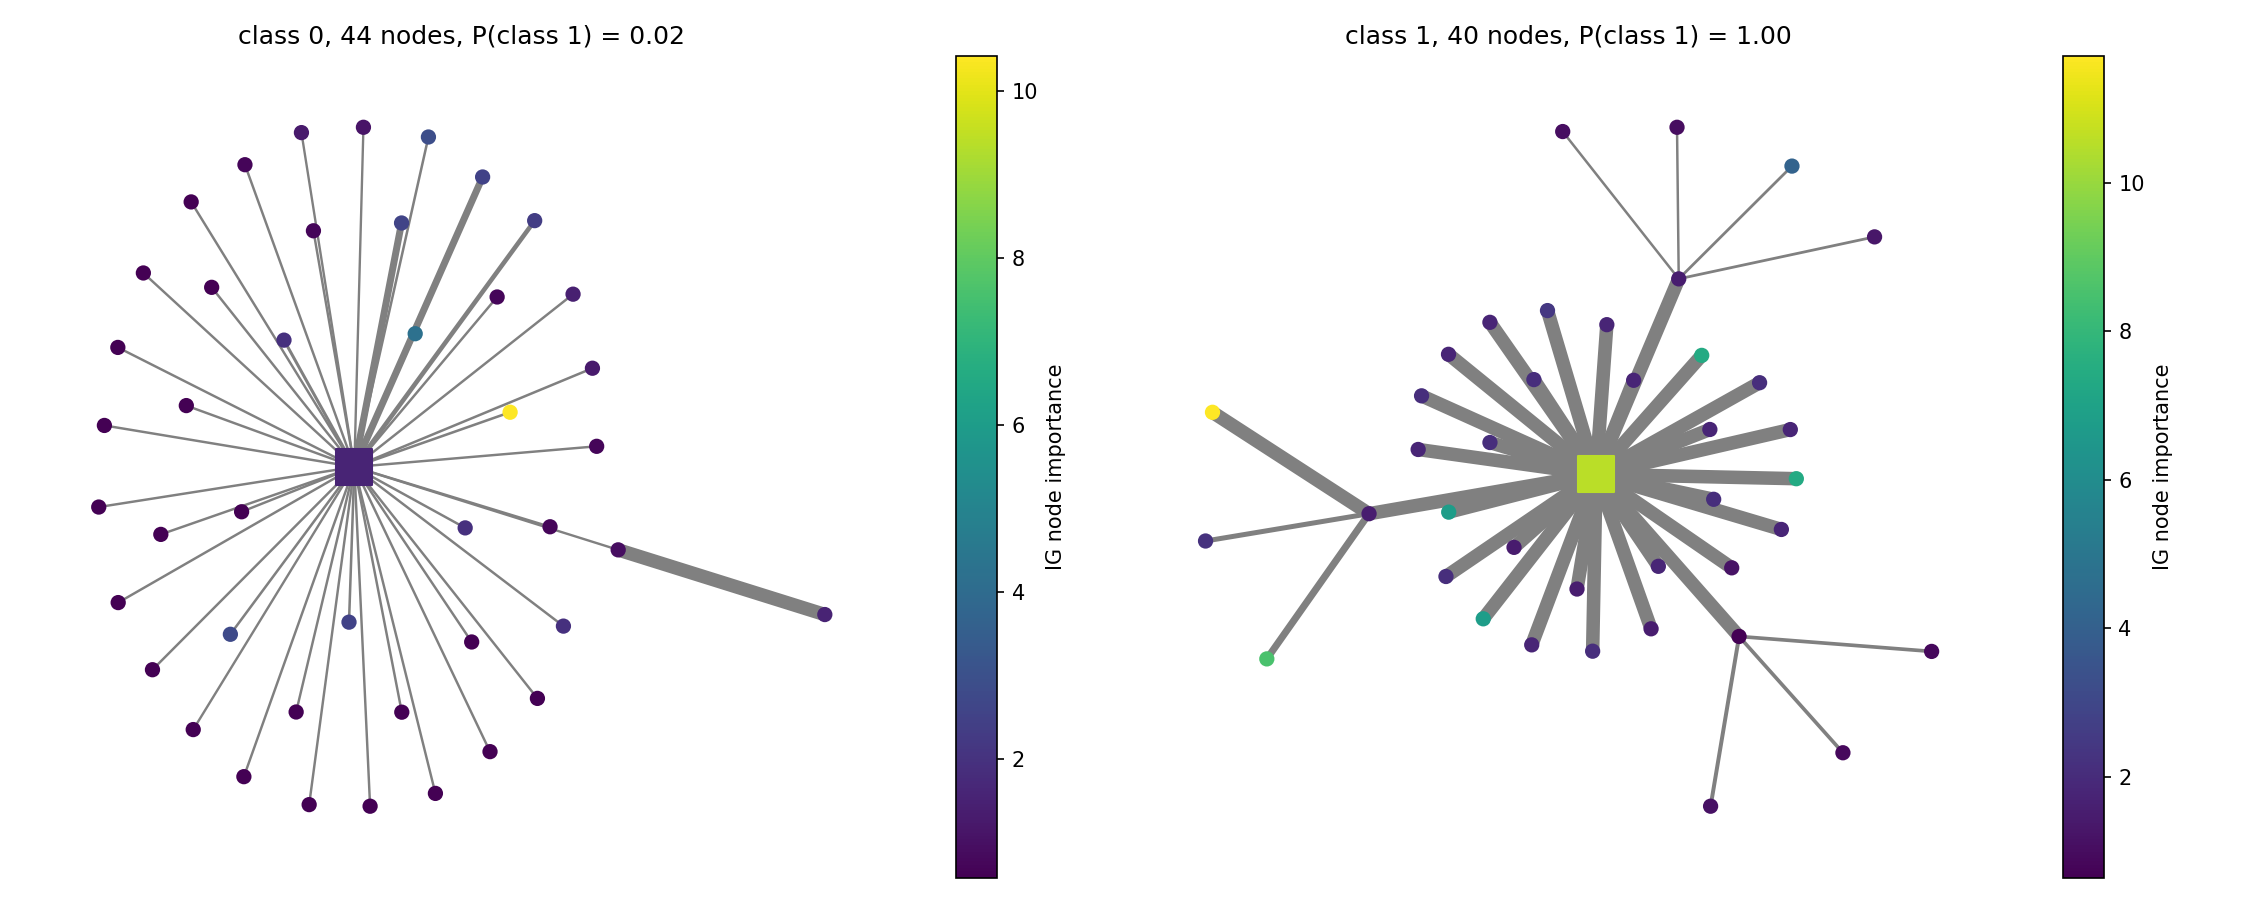

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for a, c in zip(ax, [0, 1]):
    j = min((j for j, i in enumerate(idx) if y_test[i] == c and (p_best[i] > .5) == c), key=lambda j: abs(test_set[idx[j]].num_nodes - 40))
    i = idx[j]
    G = to_networkx(raw['test'][i], to_undirected=True)
    node = E['Integrated Gradients'][j][0].abs().sum(1).numpy()
    W = attention(test_set[i].clone().to(device))[-1]
    edge_lift = len(W) * (W + W.T) / 2
    pos = nx.kamada_kawai_layout(G)
    kw = dict(ax=a, cmap='viridis', vmin=node.min(), vmax=node.max())
    nx.draw_networkx_edges(G, pos, ax=a, width=[0.5 + 1.5 * min(edge_lift[u, v], 4) for u, v in G.edges()], edge_color='grey')
    pc = nx.draw_networkx_nodes(G, pos, nodelist=list(range(1, len(node))), node_color=node[1:], node_size=40, **kw)
    nx.draw_networkx_nodes(G, pos, nodelist=[0], node_color=node[:1], node_size=300, node_shape='s', **kw)
    fig.colorbar(pc, ax=a, label="IG node importance")
    a.set_title(f"class {c}, {len(node)} nodes, P(class 1) = {p_best[i]:.2f}"); a.axis('off')
plt.tight_layout(); plt.savefig('gt_explained_cascades.png', dpi=150); plt.show()

## 38. Save the results

Everything needed to compare this model with the other two goes into one JSON file. The per-run test probabilities are saved too, so the three models' errors can later be compared graph by graph.

In [38]:
import json
res = dict(model='GraphGPS', dataset='UPFD gossipcop, content features', best_config=best,
           baseline=base.agg(['mean', 'std']).to_dict(), tuned=tuned.agg(['mean', 'std']).to_dict(), tuned_runs=tuned.to_dict('list'),
           ablation_input=table(abl).to_dict('index'), ablation_model=table(arch).to_dict('index'),
           depth={f'root={r}, layers={L}': [v.acc.mean(), v.acc.std()] for (r, L), v in depth.items()},
           efficiency=eff, size_sweep=sizes.to_dict('records'),
           edge_removal={str(k): v for k, v in drop.items()}, feature_noise={str(k): v for k, v in noise.items()},
           label_fraction={str(k): v for k, v in labels.items()},
           occlusion=occl.to_dict('index'), fidelity={f'{m}, k={k}': v for (m, k), v in fid.to_dict('index').items()},
           explanation_focus=focus.to_dict('index'), explainer_seconds_per_graph=secs,
           attention_lift={f'layer {l + 1}, d={d}': np.mean(v) for (l, d), v in lift.items()},
           attention_news_node_lift={f'layer {l + 1}': np.mean(v) for l, v in root_lift.items()})
json.dump(res, open('gt_upfd_results.json', 'w'), indent=1, default=float)
np.save('gt_upfd_test_probs.npy', P)
search.to_csv('gt_upfd_search.csv', index=False)
print("saved:", ', '.join(sorted(res)))

saved: ablation_input, ablation_model, attention_lift, attention_news_node_lift, baseline, best_config, dataset, depth, edge_removal, efficiency, explainer_seconds_per_graph, explanation_focus, feature_noise, fidelity, label_fraction, model, occlusion, size_sweep, tuned, tuned_runs


## 39. Conclusion

The whole notebook ran in about 215 minutes on a Kaggle T4.

**Milestone 2.** Cascade size alone gives 0.752 test accuracy. The plain GPS model reaches 0.969 ± 0.006 and the tuned one 0.978 ± 0.003 over ten fresh seeds, with macro-F1 0.978 and ROC-AUC 0.992. The chosen configuration has 4 GPS layers of width 128 with 4 attention heads, max readout, no root shortcut, no dropout, learning rate $10^{-3}$, weight decay $10^{-5}$ and batch size 64. The next configurations lie within about one standard deviation of it on validation, so the choice among them is not significant.

**What the model uses.**

- The node features carry most of the signal. With constant features the model falls to 0.816. That is still 6 points above size alone, and above the 0.744 the GCN notebook gets in the same test, so attention with positional encodings gets more out of the bare cascade shape than message passing does.
- The particular edges add little. Without edges ($A=I$) the model loses 0.001, with a random tree 0.002, and with parent $\rightarrow$ child edges 0.001. Unlike for the GCN, edge direction does not matter, because attention connects every pair of nodes anyway.
- The text block matters more than the profile block: text only gives 0.972, profile only 0.954.
- The news node alone gives 0.961. The users add about two points.
- Inside the GPS layer, global attention is the part that matters. Dropping the GIN branch changes nothing (0.979), dropping attention costs 1.8 points (0.961). Positional encodings, the readout (mean 0.979, sum 0.975) and the root shortcut each move accuracy by at most 0.003, within seed noise.

**Depth.** From one to eight layers, with or without the root shortcut, accuracy stays between 0.976 and 0.979. Unlike the GCN, eight layers do not collapse: a single attention layer already sees the whole cascade, and each GPS layer has residual connections and batch norm.

**Visualisation.** The silhouette score rises from 0.149 for the mean raw features to 0.536 for the GPS embedding, which splits the classes into separate groups of clusters. Most misclassified graphs sit inside a cluster of the other class.

**Efficiency.** The tuned model has 717k parameters, trains at 0.76 s per epoch with 275 MB of peak GPU memory, and scores all 3,826 test graphs in 0.66 s (8 ms for a single graph, mostly overhead). Width 16 (14k parameters) still reaches 0.968 and width 64 reaches 0.974; above 128 accuracy stops rising while the epoch time grows 4.5 times up to width 512. Against the tuned GCN (25k parameters, 0.22 s per epoch, 16 MB), the transformer costs 28 times the parameters, 3.4 times the epoch time and 17 times the memory for 0.8 points of accuracy.

**Robustness.** Removing half of the edges at test time costs only 0.4 points (0.974); the GCN lost 7. Feature noise up to $\sigma=1$ costs 0.5 points and $\sigma=2$ costs 3.4 (0.944). With 5% of the training labels (54 graphs) accuracy is 0.852, with 10% already 0.939, and with 25% within one point of the full set.

**Topology.** As for the GCN, errors concentrate on cascades whose size is atypical for their class: small class-0 cascades (at most 19 nodes, accuracy 0.756) and large class-1 cascades (more than 83 nodes, 0.943). Over the whole test set the least star-like cascades (star share below 0.67, accuracy 0.958) and those whose news node has at most 13 direct retweets (0.960) are the hardest. 40 test graphs are misclassified by all ten runs, against 89 for the GCN.

**Explainability.**

- *Occlusion.* Zeroing the profile block hardly matters (0.974). Zeroing the text block of every node, or only the features of the news node, makes the model predict the same class for every graph (0.501 and 0.499). Shuffling users between graphs keeps every feature vector realistic and still drops accuracy to 0.528, so the model depends on which users joined a cascade, not only on the news itself.
- *Fidelity.* Edge explanations stay below 0.02 for every method, random included, in line with the edge ablations. Node fidelity is about 0.40 for every method and every $k$, **random included**: zeroing 5% of the nodes at random moves the prediction as much as zeroing the ones the explainers rank highest. An all-zero node lies far outside the training data, so the model reacts to the removal itself and not to which node was removed. Removal-based fidelity therefore cannot rank the explainers for this model; for the GCN, random nodes gave only 0.02.
- *Focus.* The three node-level methods put 4% to 5% of the importance on the news node, close to the uniform 3.7%; for the GCN it was 42% to 52%. They disagree on the feature blocks: GNNExplainer and Integrated Gradients weigh a text column above a profile column, Saliency the reverse.
- *Attention.* Layer 1 gives the news node almost no attention (lift 0.0002), while layers 2, 3 and 4 give it 20.6, 9.1 and 5.8 times its uniform share. The last layer also looks 3 to 5 hops away (lift 2.4 to 3.1), so it does use its global reach. The tuned model has no root shortcut, but attention builds one. The gradient methods, by contrast, rate the news node no higher than an average node, so high attention does not mean high importance for the output.
- *Cost.* Once trained, PGExplainer is the cheapest at 0.010 s per graph, then Saliency (0.027 s), Integrated Gradients (0.89 s) and GNNExplainer (4.1 s).